# 00. Calibration of the SP mixture on one dataset

This notebook gives the parameters of Table 1 of the paper for one dataset. It runs the
chain of `src/calibration.py` step by step and shows a figure for each step. The same
chain is run on all datasets by `scripts/calibrate_all.py`, which writes
`out/00_dataset_calibration.csv`.

The steps are the following.

1. **Territory.** Border in a metric CRS, and reference radius of the SP fractal,
   R_ref = 0.5 × perimeter / 2π.
2. **Data 2PCF.** Landy-Szalay estimator, fit of ξ(r) = (r/r0)^(−γ).
3. **Branching factor η.** Number of KMeans clusters that maximises the silhouette score.
4. **m-scan.** The points are sorted by decreasing mark (population, or density). The m
   first points form the set A and the others the set B. The structured part of the
   dataset is the split m* that minimises ∫|ξ_AB(r)|, that is, the split for which A and
   B are the least cross-correlated.
5. **SP fractal.** At least m* nodes inside the territory, with λ = η^(1/(2−γ)), and a
   check of its slope against the data.
6. **Dilution.** Uniform points are added so that the amplitude of the mixture matches
   the data, ρ = ⟨ξ_data/ξ_SP⟩ and n_rand = m_SP (ρ^(−1/2) − 1). The mixture is then
   randomly thinned down to the N nodes of the dataset.

The default dataset is Belgium (815 cities), whose files are distributed with the
repository. The other datasets need the local files listed in the README. The random
catalogues of the 2PCF are not seeded, so two runs differ slightly. The values used in
the paper are stored in `out/00_dataset_calibration_reference.csv`, and the last cell
compares the two.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import synthesis_utils as su
import calibration as cal
from sp_helpers import power_law, build_sp_model, _xi_mean, _align

DATASET = "Belgium Cities"          # any key of su.DATASETS whose files are present
N_SCAN = 40                         # number of splits of the m-scan
N_REAL = 5                          # final realisations of the mixture
SEED = 42                           # seed of the SP draw

ds = su.DATASETS[DATASET]
print(f"{DATASET}: CRS {ds['crs']}, rmax = {ds['rmax'] / 1e3:.0f} km, "
      f"mark = '{ds['threshold_variable']}'")
print("2PCF parameters:", cal.PCF_PARAMS, " fit bins:", cal.FIT_RANGE)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
C_DATA, C_SP, C_MIX, C_RAND = "#000000", "#0072B2", "#D55E00", "#999999"


def centres(r_edges, xi):
    """Geometric bin centres matching the length of xi."""
    r_edges = np.asarray(r_edges)
    if len(r_edges) == len(xi) + 1:
        return np.sqrt(r_edges[:-1] * r_edges[1:])
    return r_edges[:len(xi)]

Belgium Cities: CRS EPSG:3812, rmax = 200 km, mark = 'population'
2PCF parameters: {'N_run': 5, 'size': 7000, 'k': 3, 'scale': 'log', 'nbins': 20, 'bootstrap_size': 10000, 'bootstrap_N_real': 10}  fit bins: (1, 19)


## 1. Territory and data

N = 815 points inside the territory, R_ref = 101.6 km, area = 30,656 km²


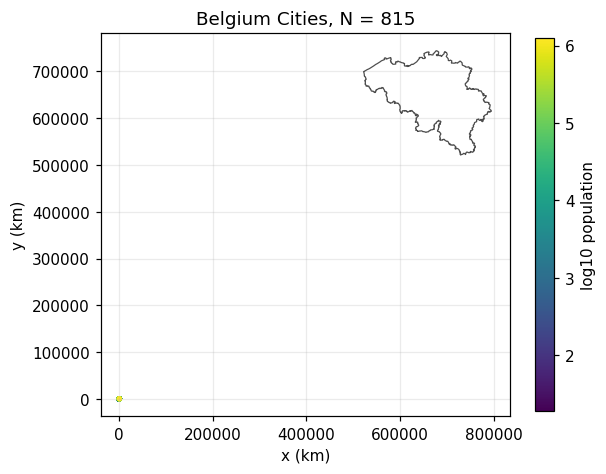

In [2]:
gdf_edge, R_ref = cal.load_territory(ds)
gdf_projected, coords, marks = cal.load_points(ds, gdf_edge)
N = len(coords)
print(f"N = {N:,} points inside the territory, R_ref = {R_ref / 1e3:.1f} km, "
      f"area = {gdf_edge.area.sum() / 1e6:,.0f} km²")

fig, ax = plt.subplots(figsize=(6, 5.5))
gdf_edge.boundary.plot(ax=ax, color="0.3", lw=.8)
order = np.argsort(marks)
sc = ax.scatter(coords[order, 0] / 1e3, coords[order, 1] / 1e3,
                c=np.log10(np.maximum(marks[order], 1)), s=6, cmap="viridis")
plt.colorbar(sc, ax=ax, shrink=.8, label=f"log10 {ds['threshold_variable']}")
ax.set_aspect("equal"); ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
ax.set_title(f"{DATASET}, N = {N:,}")
plt.show()

## 2. Data 2PCF and power-law fit

gamma = 0.9045 ± 0.1835, r0 = 3.04 ± 0.82 km   (10 s)


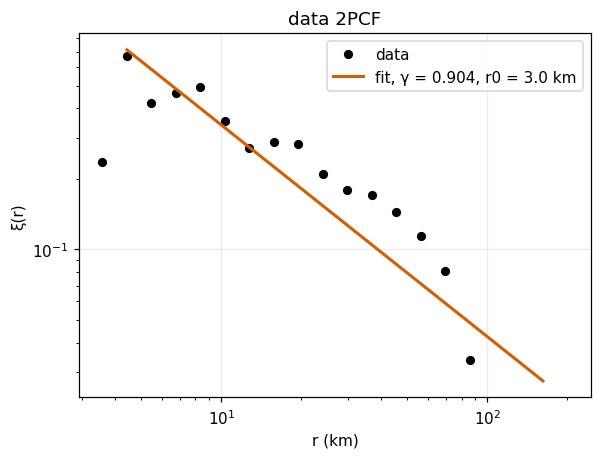

In [3]:
t0 = time.time()
r_edges, l_xi = cal.data_2pcf(gdf_projected, gdf_edge, ds["crs"], ds["rmax"])
gamma, r0, gamma_err, r0_err = cal.fit_gamma(r_edges, l_xi)
xi_data = _xi_mean(r_edges, l_xi)
print(f"gamma = {gamma:.4f} ± {gamma_err:.4f}, r0 = {r0 / 1e3:.2f} ± {r0_err / 1e3:.2f} km"
      f"   ({time.time() - t0:.0f} s)")

rc = centres(r_edges, xi_data)
a, b = cal.FIT_RANGE
fig, ax = plt.subplots(figsize=(6, 4.3))
ax.plot(rc / 1e3, xi_data, "o", color=C_DATA, ms=5, label="data")
rf = rc[a:b]
ax.plot(rf / 1e3, power_law(rf, gamma, r0), "-", color=C_MIX, lw=2,
        label=f"fit, γ = {gamma:.3f}, r0 = {r0 / 1e3:.1f} km")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (km)"); ax.set_ylabel("ξ(r)"); ax.legend()
ax.set_title("data 2PCF")
plt.show()

## 3. Branching factor η

eta = 2  (silhouette 0.4663)


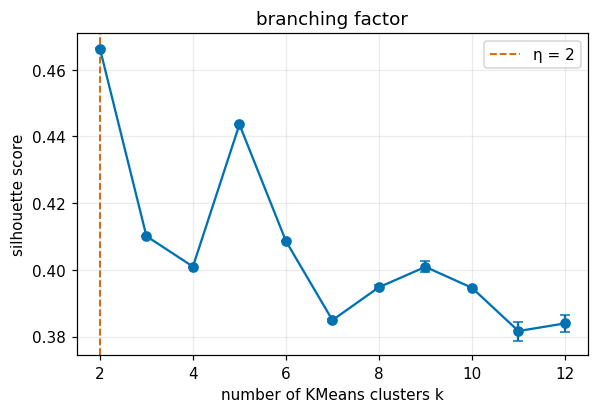

In [4]:
eta, k_values, sil_means, sil_stds = cal.silhouette_eta(coords)
print(f"eta = {eta}  (silhouette {sil_means.max():.4f})")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.errorbar(k_values, sil_means, yerr=sil_stds, fmt="o-", color=C_SP, capsize=3)
ax.axvline(eta, color=C_MIX, ls="--", lw=1.2, label=f"η = {eta}")
ax.set_xlabel("number of KMeans clusters k"); ax.set_ylabel("silhouette score")
ax.legend(); ax.set_title("branching factor")
plt.show()

## 4. m-scan on the cross-2PCF

For each split m, A is the set of the m points with the largest mark and B the rest.
When A and B are drawn from the same process, ξ_AB is close to ξ_data. When A holds the
structured part and B a background, ξ_AB is close to zero. The integral ∫|ξ_AB| is
therefore minimal at the split that best separates a structured part from a background.

m-scan:   0%|          | 0/40 [00:00<?, ?it/s]

m-scan:  40%|████      | 16/40 [00:23<00:35,  1.50s/it]

m-scan:  60%|██████    | 24/40 [00:47<00:33,  2.11s/it]

m-scan:  80%|████████  | 32/40 [01:12<00:19,  2.48s/it]

m-scan: 100%|██████████| 40/40 [01:37<00:00,  2.69s/it]

m-scan: 100%|██████████| 40/40 [01:37<00:00,  2.43s/it]

m* = 718  (m*/N = 0.881)   (129 s)


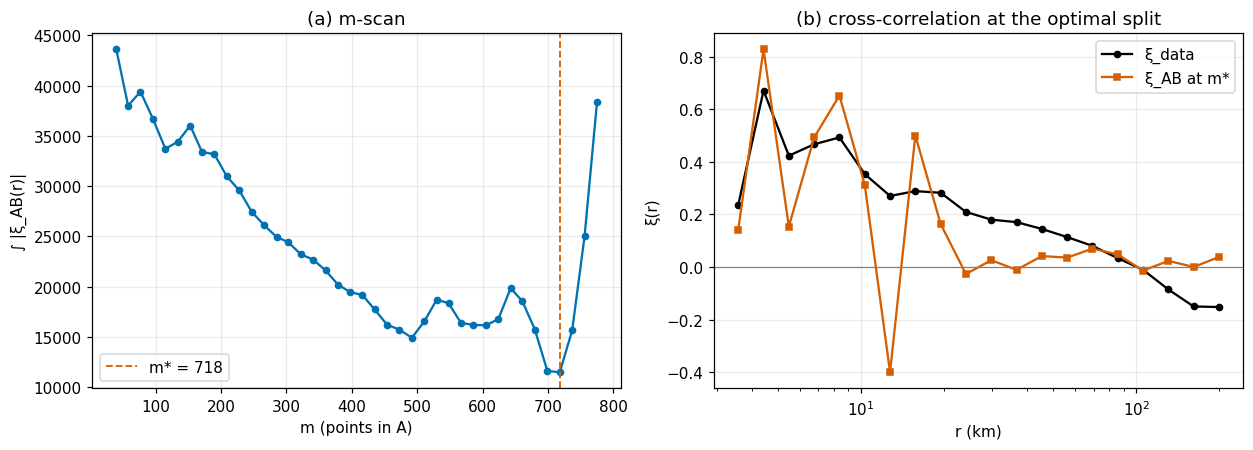

In [5]:
t0 = time.time()
coords_sorted = coords[np.argsort(marks)[::-1]]
m_arr, int_arr, scan = cal.m_scan(coords_sorted, xi_data, r_edges, gdf_edge, ds["crs"],
                                  ds["rmax"], n_scan=N_SCAN)
m_star, i_star = cal.find_m_star(m_arr, int_arr)
print(f"m* = {m_star:,}  (m*/N = {m_star / N:.3f})   ({time.time() - t0:.0f} s)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axes[0]
ax.plot(m_arr, int_arr, "o-", color=C_SP, ms=4)
ax.axvline(m_star, color=C_MIX, ls="--", lw=1.2, label=f"m* = {m_star:,}")
ax.set_xlabel("m (points in A)"); ax.set_ylabel("∫ |ξ_AB(r)|"); ax.legend()
ax.set_title("(a) m-scan")

ax = axes[1]
xi_c, r_c_e = scan[i_star]["xi"], scan[i_star]["r_edges"]
ax.plot(rc / 1e3, xi_data, "o-", color=C_DATA, ms=4, label="ξ_data")
ax.plot(centres(r_c_e, xi_c) / 1e3, xi_c, "s-", color=C_MIX, ms=4,
        label=f"ξ_AB at m*")
ax.axhline(0, color="0.5", lw=.8)
ax.set_xscale("log"); ax.set_xlabel("r (km)"); ax.set_ylabel("ξ(r)"); ax.legend()
ax.set_title("(b) cross-correlation at the optimal split")
plt.tight_layout(); plt.show()

## 5. SP fractal

The fractal is built with the branching factor η and the slope γ of the data, so that
λ = η^(1/(2−γ)). Its depth L is the smallest one that leaves at least m* nodes inside
the territory. Its own 2PCF should have the slope of the data. Its amplitude is higher,
since the fractal alone has no background.

In [6]:
np.random.seed(SEED)                # the SP draw uses the global random stream
pos_sp, L_sp, lamb_sp = build_sp_model(m_star, eta, gamma, R_ref, gdf_edge, ds["crs"])
m_sp = len(pos_sp)
r_e_sp, l_xi_sp = cal.sp_2pcf(pos_sp, gdf_edge, ds["crs"], ds["rmax"])
xi_sp = _xi_mean(r_e_sp, l_xi_sp)
r_e_sp = r_e_sp[:len(xi_sp)]
gamma_sp, r0_sp, gamma_sp_err, _ = cal.fit_gamma(r_e_sp, l_xi_sp)
print(f"lambda = {lamb_sp:.3f}, L = {L_sp}, m_SP = {m_sp:,}, "
      f"gamma_SP = {gamma_sp:.4f} ± {gamma_sp_err:.4f}  (data {gamma:.4f})")

lambda = 1.883, L = 10, m_SP = 1,016, gamma_SP = 0.9055 ± 0.0215  (data 0.9045)


## 6. Dilution and final mixture

The amplitude ratio ρ is the mean of ξ_data/ξ_SP over the bins where ξ_SP > 0. It
depends on the SP draw, and section 6bis measures how much.

rho = 0.0930, n_rand = 2,315
final mixture: 815 nodes, 238 SP and 577 random (SP fraction 0.292)


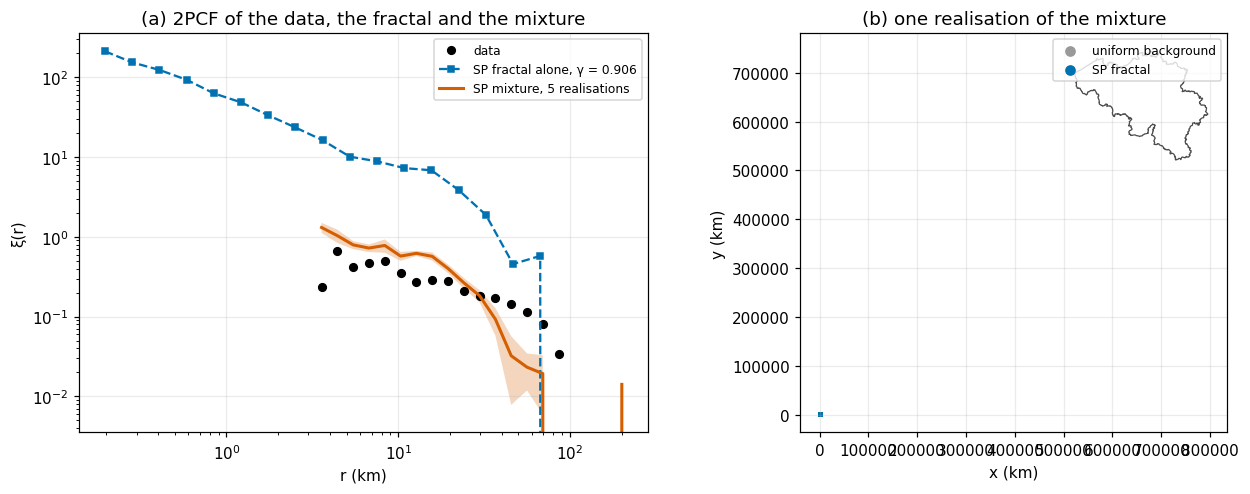

In [7]:
rho, n_rand = cal.dilution(xi_data, r_edges, xi_sp, r_e_sp, m_sp)
pos_mix, labels = cal.build_mixture(pos_sp, n_rand, gdf_edge, ds["crs"])
xi_f_mean, xi_f_std, pos_f, lab_f = cal.final_realisations(
    pos_mix, labels, N, gdf_edge, ds["crs"], r_edges, ds["rmax"], n_real=N_REAL)
n_sp_final = int((lab_f == 0).sum())
print(f"rho = {rho:.4f}, n_rand = {n_rand:,}")
print(f"final mixture: {N:,} nodes, {n_sp_final:,} SP and {N - n_sp_final:,} random "
      f"(SP fraction {n_sp_final / N:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.plot(rc / 1e3, xi_data, "o", color=C_DATA, ms=5, label="data")
ax.plot(centres(r_e_sp, xi_sp) / 1e3, xi_sp, "s--", color=C_SP, ms=4,
        label=f"SP fractal alone, γ = {gamma_sp:.3f}")
ax.fill_between(rc / 1e3, xi_f_mean - xi_f_std, xi_f_mean + xi_f_std, color=C_MIX,
                alpha=.25, lw=0)
ax.plot(rc / 1e3, xi_f_mean, "-", color=C_MIX, lw=2,
        label=f"SP mixture, {N_REAL} realisations")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (km)"); ax.set_ylabel("ξ(r)"); ax.legend(fontsize=8)
ax.set_title("(a) 2PCF of the data, the fractal and the mixture")

ax = axes[1]
gdf_edge.boundary.plot(ax=ax, color="0.3", lw=.8)
ax.scatter(pos_f[lab_f == 1, 0] / 1e3, pos_f[lab_f == 1, 1] / 1e3, s=4, color=C_RAND,
           label="uniform background")
ax.scatter(pos_f[lab_f == 0, 0] / 1e3, pos_f[lab_f == 0, 1] / 1e3, s=4, color=C_SP,
           label="SP fractal")
ax.set_aspect("equal"); ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
ax.legend(fontsize=8, markerscale=3); ax.set_title("(b) one realisation of the mixture")
plt.tight_layout(); plt.show()

## 6bis. Sensitivity of ρ to the SP draw

The fractal is redrawn ten times with the same m*, η and γ, and ρ is recomputed for each
draw. The mean of the ratio is sensitive to the bins at large r, where ξ_data can be
negative while ξ_SP is barely positive. A single such bin can bring the mean close to
zero or below (ρ is then clipped to 10⁻⁴). The median of the ratio is shown for
comparison, it is not used by the calibration.

In [8]:
rho_rows = []
for s in range(10):
    np.random.seed(s)
    pos_s, L_s, _ = build_sp_model(m_star, eta, gamma, R_ref, gdf_edge, ds["crs"])
    r_s, l_s = cal.sp_2pcf(pos_s, gdf_edge, ds["crs"], ds["rmax"])
    x_s = _xi_mean(r_s, l_s)
    r_s = r_s[:len(x_s)]
    al = _align(r_s, x_s, r_edges)
    m = al[1:] > 1e-6
    ratio = xi_data[1:][m] / al[1:][m]
    rho_rows.append(dict(seed=s, L=L_s, m_SP=len(pos_s), mean_ratio=ratio.mean(),
                         median_ratio=np.median(ratio), min_ratio=ratio.min()))
rho_tab = pd.DataFrame(rho_rows)
print(rho_tab.round(4).to_string(index=False))
print(f"\nmean ratio over the draws: {rho_tab.mean_ratio.mean():.3f} ± "
      f"{rho_tab.mean_ratio.std():.3f}   (this run, seed {SEED}: rho = {rho:.4f})")

  L=10: 688 inside < 718, trying L=11


  L=10: 638 inside < 718, trying L=11


  L=10: 630 inside < 718, trying L=11


  L=10: 442 inside < 718, trying L=11


 seed  L  m_SP  mean_ratio  median_ratio  min_ratio
    0 11  2048      0.1351        0.0710     0.0272
    1 10   916      0.2367        0.0905     0.0293
    2 10  1024     -0.0184        0.0496    -1.3246
    3 11  2048      0.1432        0.0671     0.0445
    4 10   810      0.2753        0.0598    -0.1909
    5 10   960      0.0691        0.0663    -0.4850
    6 10   738      0.1275        0.0997     0.0216
    7 11  2048      0.0372        0.0622    -0.3679
    8 11  1480      0.1475        0.0905     0.0338
    9 10   788      0.0854        0.0756    -0.5007

mean ratio over the draws: 0.124 ± 0.088   (this run, seed 42: rho = 0.0930)


## 7. Comparison with the values of the paper

The 2PCF uses random catalogues without a fixed seed, so γ, η and m* can move a little
between runs. η and the depth L are integers and usually do not change. m* is the
least stable quantity, since the m-scan integral is flat around its minimum.

In [9]:
res = dict(name=DATASET, N=N, R_ref_m=R_ref, rmax=ds["rmax"], gamma=gamma,
           gamma_err=gamma_err, r0_m=r0, r0_err_m=r0_err, eta=eta,
           silhouette=float(sil_means.max()), m_min=int(m_arr.min()),
           m_max=int(m_arr.max()), m_star=m_star, lamb=lamb_sp, L=L_sp, m_SP=m_sp,
           gamma_SP=gamma_sp, gamma_SP_err=gamma_sp_err, rho=rho, n_rand=n_rand,
           final_SP=n_sp_final, final_random=N - n_sp_final)

ref_tab = pd.read_csv(ROOT / "out" / "00_dataset_calibration_reference.csv")
cmp = pd.DataFrame({"this run": pd.Series(res)})
if DATASET in set(ref_tab["name"]):
    cmp["paper"] = ref_tab.set_index("name").loc[DATASET]
cmp = cmp.drop(index=["name"])
cmp

,this run,paper
N,815,815
R_ref_m,101645.45493,102700
rmax,200000,200000
gamma,0.904485,0.8078
gamma_err,0.183513,0.1247
r0_m,3036.786919,3083
r0_err_m,824.58194,860
eta,2,2
silhouette,0.46632,0.4663
m_min,40,40
